# COMPRESSIBLE FLUID MECHANICS
# ME510 – LAB #1
# “QUASI 1-D NOZZLE FLOW”
__________
## Import Global Dependencies and Data
_________

In [1]:
import numpy as np
import math
from scipy.optimize import brentq
from matplotlib import pyplot as plt

# Load measured pressure data from text file and calculate pressure ratios (P/P0)

# P_taps = np.loadtxt("C:/Users/lamor/OneDrive/Documents/BYUINFO/Fall 2026/ME EN 510/Labs/Lab1/BryceandEzra.txt",skiprows = 1)
# P_taps_table = np.atleast_2d(P_taps)
# print("P_taps_table:")
# print("\t".join(f"Column {i + 1}" for i in range(P_taps_table.shape[1])))
# for row in P_taps_table:
#     print("\t".join(str(value) for value in row))

P_taps_new = np.loadtxt(
    "C:/Users/lamor/OneDrive/Documents/BYUINFO/Fall 2026/ME EN 510/Labs/Lab1/Makayle_F26.txt",
    skiprows=1,
)
P_taps_new_table = np.atleast_2d(P_taps_new)
P_taps_new_back = P_taps_new[:, -1]

print("P_taps_new_back: " + str(P_taps_new_back))
print("P_taps_new_table:")
print("\t".join(f"Column {i + 1}" for i in range(P_taps_new_table.shape[1])))
for row in P_taps_new_table:
    print("\t".join(str(value) for value in row))

P_taps_new_back: [12.015821 11.477283 10.763375 10.001945  9.342434  8.749715  7.914763
  6.085637]
P_taps_new_table:
Column 1	Column 2	Column 3	Column 4	Column 5	Column 6	Column 7	Column 8
11.683121	11.594428	11.731856	11.839267	11.893583	11.944832	11.988889	12.015821
10.798015	10.595885	10.90187	11.109147	11.222773	11.331713	11.427644	11.477283
9.588802	9.138658	9.766297	10.134424	10.341041	10.531211	10.69339	10.763375
8.645082	6.461065	8.544944	9.089083	9.413062	9.689256	9.908963	10.001945
8.627993	5.461119	5.183658	7.936973	8.572519	8.952542	9.214922	9.342434
8.639989	5.461083	4.724287	4.579938	7.348316	8.194938	8.584234	8.749715
8.623316	5.461056	4.715105	4.164715	3.699364	6.574609	7.476679	7.914763
8.614622	5.460794	4.761722	4.171156	3.652592	3.288184	5.409716	6.085637


### Known Parameters

In [2]:
T0 = 72  # deg F
T0_R = T0 + 459.67  # deg R
P0 = 64.54  # mmHg
Pamb = 25.49  # in Hg
P_atm = Pamb * 0.491154  # convert in Hg to psi
w = 0.375  # in
l = 4.2  # in
R_air = 287 * 5.97994  # ft*lbf/(slug*R)
gamma = 1.4

X_taps = np.array([-0.2, 0.3, 1, 1.7, 2.4, 3.1, 3.8])


def h(x):
    """definition of the diverging portion of the nozzle
    4.2 in long
    0.375 in deep
    defined height below where x is distance from the throat
    Args:
        x : Distance from the throat (in)
    Returns:
        Height (h) of the nozzle at distance x from the throat (in)
    """
    return 0.4 + 0.04762 * x


def A_cross(x):
    """cross-sectional area of the nozzle given distance x from the throat and width w

    Args:
        x : Distance from the throat (in)

    Returns:
        Cross-sectional area of the nozzle at distance x from the throat (in^2)
    """
    return h(x) * w


def area_star_ratio(M, g=gamma):  # A/A*, Eq. 3.23
    """Calculate the area ratio A/A* given the Mach number M and specific heat ratio g.
    Args:
        M : Mach number
        g : specific heat ratio (default is gamma)
    Returns:
        Area ratio A/A* (dimensionless)
    """
    return (1 / M) * ((2 / (g + 1)) * (1 + (g - 1) / 2 * M**2)) ** (
        (g + 1) / (2 * (g - 1))
    )


def p_p0(M, g=gamma):  # p0/p, Eq. 3.15
    """Calculate the pressure ratio p0/p given the Mach number M and specific heat ratio g.

    Args:
        M : Mach number
        g : specific heat ratio (default is gamma)

    Returns:
        Pressure ratio p0/p (dimensionless)
    """
    return (1 + (g - 1) / 2 * M**2) ** (-g / (g - 1))


def M_from_AR(AR, supersonic=False):
    """Find Mach number from area ratio A/A*.
    If supersonic is True, find the supersonic solution.
    Otherwise, find the subsonic solution.

    Args:
        AR : Area ratio A/A*
        supersonic : Boolean flag to choose supersonic or subsonic solution

    Returns:
        Mach number corresponding to the given area ratio
    """
    if supersonic:
        return brentq(lambda M: area_star_ratio(M) - AR, 1.0001, 10)
    else:
        return brentq(lambda M: area_star_ratio(M) - AR, 1e-6, 0.9999)

def M_from_PR(PR, g=gamma):
    """Mach number from static-to-stagnation pressure ratio p/p0, Eq. 3.16.
    Args:
        PR : Static-to-stagnation pressure ratio p/p0
        g : specific heat ratio (default is gamma)

    Returns:
        Mach number corresponding to the given pressure ratio
    """
    return np.sqrt(2 / (g - 1) * (PR ** (-(g - 1) / g) - 1))

def shock(M1, g=gamma):  # M2, p2/p1, p02/p01
    """Calculate the properties across a normal shock.

    Args:
        M1 : Mach number before the shock
        g : specific heat ratio

    Returns:
        M2 : Mach number after the shock
        p2_1 : Pressure ratio p2/p1 across the shock
        p0_r : Stagnation pressure ratio p02/p01 across the shock
    """
    M2 = np.sqrt((M1**2 + 2 / (g - 1)) / (2 * g / (g - 1) * M1**2 - 1))
    p2_1 = 1 + 2 * g / (g + 1) * (M1**2 - 1)
    p0_r = ((g + 1) * M1**2 / (2 + (g - 1) * M1**2)) ** (g / (g - 1)) * (
        (g + 1) / (2 * g * M1**2 - (g - 1))
    ) ** (1 / (g - 1))
    return M2, p2_1, p0_r

## A
_____
### Calculate the theoretical Pback for which the flow “just” reaches M=1 at the throat and M≤1 throughout.  



In [3]:
# Calculate cross sectional areas
A_star_1 = A_cross(0)
A_exit = A_cross(l)
A_taps = A_cross(X_taps) ## note first value incorrect for converging portion of nozzle
A_taps[0] = 0.1591 # correct for area in converging section


print("A_exit/A_star_1: " + str(A_exit / A_star_1))
print("Patm : " + str(P_atm) + " psi")

P_exit_sub = p_p0(M_from_AR(A_exit / A_star_1, supersonic=False))
print("p/p0 at exit: " + str(P_exit_sub))

P_exit_sub = P_exit_sub * P_atm
print("P_exit_sub: " + str(P_exit_sub) + " psi")



A_exit/A_star_1: 1.5000099999999996
Patm : 12.51951546 psi
p/p0 at exit: 0.8805186978687124
P_exit_sub: 11.023667450786412 psi


_____
### Calculate the mass flow rate for this setting.


In [4]:
m_dot = (
    (P_atm * A_star_1 / math.sqrt(R_air * T0_R))
    * np.sqrt(gamma)
    * ((gamma + 1) / 2) ** (-(gamma + 1) / (2 * (gamma - 1)))
)
print("m_dot: " + str(m_dot) + " slug*ft/s")
print("m_dot (lbm/s): " + str(m_dot * 32.174) + " lbm/s")  # convert slugs/s to lbm/s

m_dot: 0.0013461350122832354 slug*ft/s
m_dot (lbm/s): 0.04331054788520081 lbm/s


## B
___
### For each of two cases you have which are above this Pback limit, calculate the theoretical P/Pambient at each tap along the nozzle.  


In [5]:

# Theoretical Calculations for Nozzle Flow


unchoked = [0, 1]
# Calculate the area ratio at the pressure taps in the diverging section
PR_back = P_taps_new_table[unchoked, 7] / P_atm

M_e = np.array([])
for i in PR_back:
    M_back = M_from_PR(i)
    M_e = np.append(M_e, M_back)
print("Mach numbers at exit with back pressure (subsonic) for case 1 and 2: " + str(M_e))

A_star_sub = A_exit / area_star_ratio(M_e)  # Use the last Mach number at the back pressure
print("A* at the back pressure (subsonic): " + str(A_star_sub))

A_ratio_taps_exp = np.zeros((len(unchoked), len(A_taps)))
A_ratio_taps_exp[0, :] = A_taps / A_star_sub[0]
A_ratio_taps_exp[1, :] = A_taps / A_star_sub[1]
print("Area ratio at the pressure taps for experiment 1 and 2 = " + str(A_ratio_taps_exp))

case_1 = A_ratio_taps_exp[0,:]
M_taps_exp_case_1 = [M_from_AR(a, supersonic=False) for a in case_1]
case_2 = A_ratio_taps_exp[1,:]
M_taps_exp_case_2 = [M_from_AR(a, supersonic=False) for a in case_2]
print("Mach numbers at the pressure taps for experiment 1: " + str(M_taps_exp_case_1))
print("Mach numbers at the pressure taps for experiment 2: " + str(M_taps_exp_case_2))

P_ratio_taps_theory_case_1 = [p_p0(M) for M in M_taps_exp_case_1]
P_ratio_taps_theory_case_2 = [p_p0(M) for M in M_taps_exp_case_2]
print("Pressure ratio at the pressure taps for experiment 1: " + str(P_ratio_taps_theory_case_1))
print("Pressure ratio at the pressure taps for experiment 2: " + str(P_ratio_taps_theory_case_2))


# Experimental Calculations for Nozzle Floww

# Calculate the experimental pressure ratio at the pressure taps (subsonic)
P_ratio_taps = P_taps_new_table[unchoked, :7] / P_atm 
case_1_P_ratio_taps_exp = P_ratio_taps[0, :]
case_2_P_ratio_taps_exp = P_ratio_taps[1, :]
print("Experimental pressure ratio at the pressure taps for experiment 1: " + str(case_1_P_ratio_taps_exp))
print("Experimental pressure ratio at the pressure taps for experiment 2: " + str(case_2_P_ratio_taps_exp))



Mach numbers at exit with back pressure (subsonic) for case 1 and 2: [0.24291771 0.35457668]
A* at the back pressure (subsonic): [0.0911805  0.12796274]
Area ratio at the pressure taps for experiment 1 and 2 = [[1.74489059 1.70384288 1.84093634 1.97802979 2.11512325 2.2522167
  2.38931015]
 [1.24333069 1.21408195 1.31176859 1.40945523 1.50714187 1.60482851
  1.70251515]]
Mach numbers at the pressure taps for experiment 1: [0.35778745892218666, 0.36799778995835214, 0.33615083108128235, 0.3097309585830134, 0.28738627748504886, 0.2681982263970097, 0.2515152903419335]
Mach numbers at the pressure taps for experiment 2: [0.557888222614049, 0.5791751295531887, 0.5152254364302719, 0.46658771817058664, 0.42767278065972325, 0.39551786495284974, 0.36833880497290217]
Pressure ratio at the pressure taps for experiment 1: [0.9153210290296229, 0.9107064746739211, 0.9247631574994702, 0.9356468349263808, 0.9442717184215429, 0.9512365959534599, 0.9569499650077804]
Pressure ratio at the pressure taps fo

___
### Plot P/Pambient vs. x at pressure tap locations for both experiment and theory.  


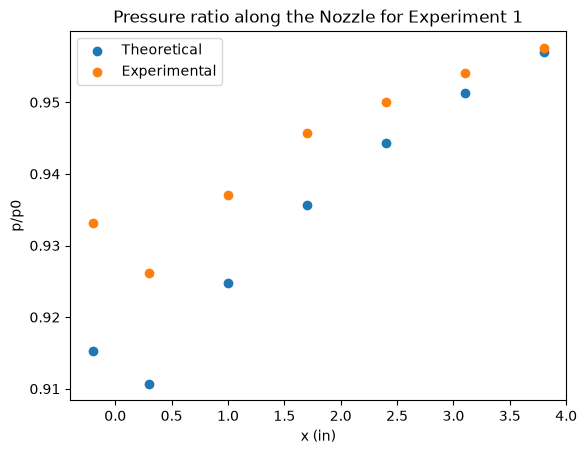

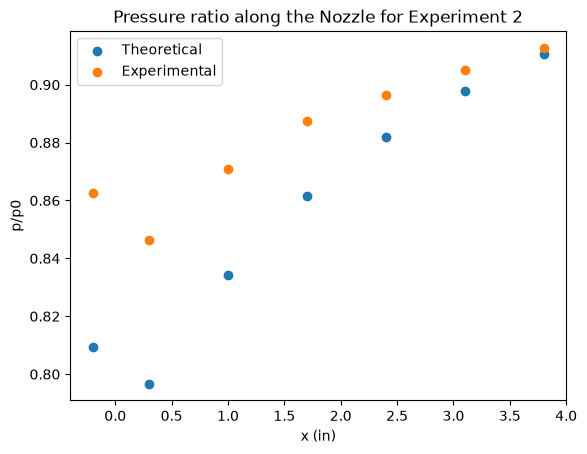

In [6]:
plt.scatter(X_taps, P_ratio_taps_theory_case_1, label="Theoretical")
plt.scatter(X_taps, case_1_P_ratio_taps_exp, label="Experimental")
plt.xlabel("x (in)")
plt.ylabel("p/p0")
plt.title("Pressure ratio along the Nozzle for Experiment 1")
plt.legend()
plt.show()

plt.scatter(X_taps, P_ratio_taps_theory_case_2, label="Theoretical")
plt.scatter(X_taps, case_2_P_ratio_taps_exp, label="Experimental")
plt.xlabel("x (in)")
plt.ylabel("p/p0")
plt.title("Pressure ratio along the Nozzle for Experiment 2")
plt.legend()
plt.show()

___
### Comment on any discrepancies between the data and theory and suggest possible explanations.

## C
___
### For each of four cases you have which were clearly choked, calculate the theoretical normal shock position (see section 4.5 in text) and compare it to shock location suggested by your pressure data. 


___
### Calculate the theoretical P/Pambient at each tap along the nozzle (upstream and downstream of shock as appropriate). 


___
### Plot P/Pambient vs. x at pressure tap locations for both experiment and theory.  


___
### Comment on any discrepancies between the data and theory and suggest 


## D
___
### For the four cases in part (c) where the normal shock was clearly positioned between the pressure tap locations, determine the theoretical value of Pback for which the predicted shock location would be the same as observed shock position. 


___
### Comment on the magnitude of these values relative to the measured values for the observed shock and whether the trends make sense.


## E
___
### Calculate the Pback that corresponds to an ideally expanded nozzle.